In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("../data/raw/PhiUSIIL_Phishing_URL_Dataset.csv")

print("Dataset loaded successfully")
print("Shape:", df.shape)

Dataset loaded successfully
Shape: (235795, 56)


In [3]:
df

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000000,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000000,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000000,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000000,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000000,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235790,660997.txt,https://www.skincareliving.com,29,www.skincareliving.com,22,0,com,100.000000,1.000000,0.522907,...,1,0,1,51,7,21,187,2,191,1
235791,77185.txt,https://www.winchester.gov.uk,28,www.winchester.gov.uk,21,0,uk,100.000000,0.785714,0.028555,...,1,0,0,50,1,7,88,0,31,1
235792,622132.txt,https://www.nononsensedesign.be,30,www.nononsensedesign.be,23,0,be,100.000000,1.000000,0.003319,...,0,0,1,27,10,30,58,2,67,1
235793,7503962.txt,https://patient-cell-40f5.updatedlogmylogin.wo...,55,patient-cell-40f5.updatedlogmylogin.workers.dev,47,0,dev,28.157537,0.465116,0.000961,...,0,0,0,0,0,3,0,0,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [5]:
counts = df['URL'].value_counts()
print(counts)

URL
https://att-104164.weeblysite.com/                              2
https://etiliseramik.com/wp-includes/vector/login.htm           2
https://snapdragon-magic-flag.glitch.me/navyfederal.org.html    2
http://my-business-108580.square.site/                          2
https://facebook-help-600674518635606.firebaseapp.com/          2
                                                               ..
https://www.skincareliving.com                                  1
https://www.winchester.gov.uk                                   1
https://www.nononsensedesign.be                                 1
https://patient-cell-40f5.updatedlogmylogin.workers.dev/        1
https://www.alternativefinland.com                              1
Name: count, Length: 235370, dtype: int64


In [6]:
df = df.drop_duplicates(subset=['URL'])

In [7]:
X = df[[
    "IsDomainIP",
    "NoOfLettersInURL",
    "NoOfDegitsInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "DegitRatioInURL",
    "LetterRatioInURL",
    "NoOfSubDomain",
    "TLDLength",
    "IsHTTPS"
    ]]
y = df["label"]

In [8]:
import re
from urllib.parse import urlparse

def features_extract(url):
    parsed_url = urlparse(url if "://" in url else "https://" + url)

    url_length = len(url)
    domain = parsed_url.netloc
    domain_length = len(domain)

    is_domain_ip = int(bool(re.match(r"^\d{1,3}(\.\d{1,3}){3}$", domain.split(":")[0])))

    no_of_letters = sum(c.isalpha() for c in url)
    no_of_digits = sum(c.isdigit() for c in url)

    no_of_other_special_chars = sum(
        not c.isalnum() and c not in "/-.:?=&_%#"
        for c in url
    )

    special_char_ratio = sum(not c.isalnum() for c in url) / max(url_length, 1)
    digit_ratio = no_of_digits / max(url_length, 1)
    letter_ratio = no_of_letters / max(url_length, 1)

    hostname = domain.split(":")[0]
    subdomain_parts = hostname.split(".")
    no_of_subdomain = max(len(subdomain_parts) - 2, 0)

    tld = subdomain_parts[-1] if len(subdomain_parts) > 1 else ""
    tld_length = len(tld)

    is_https = int(parsed_url.scheme == "https")

    return {
        # "parsedurl":parsed_url,
        # "DomainLength": domain_length,
        "IsDomainIP": is_domain_ip,
        "NoOfLettersInURL": no_of_letters,
        "NoOfDegitsInURL": no_of_digits,
        "NoOfOtherSpecialCharsInURL": no_of_other_special_chars,
        "SpacialCharRatioInURL": special_char_ratio,
        "DegitRatioInURL": digit_ratio,
        "LetterRatioInURL": letter_ratio,
        "NoOfSubDomain": no_of_subdomain,
        "TLDLength": tld_length,
        "IsHTTPS": is_https
    }

In [9]:
features_extract("https://www.gov.uk/")

{'IsDomainIP': 0,
 'NoOfLettersInURL': 13,
 'NoOfDegitsInURL': 0,
 'NoOfOtherSpecialCharsInURL': 0,
 'SpacialCharRatioInURL': 0.3157894736842105,
 'DegitRatioInURL': 0.0,
 'LetterRatioInURL': 0.6842105263157895,
 'NoOfSubDomain': 1,
 'TLDLength': 2,
 'IsHTTPS': 1}

In [10]:
features_extract("https://www.google.com")

{'IsDomainIP': 0,
 'NoOfLettersInURL': 17,
 'NoOfDegitsInURL': 0,
 'NoOfOtherSpecialCharsInURL': 0,
 'SpacialCharRatioInURL': 0.22727272727272727,
 'DegitRatioInURL': 0.0,
 'LetterRatioInURL': 0.7727272727272727,
 'NoOfSubDomain': 1,
 'TLDLength': 3,
 'IsHTTPS': 1}

In [11]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (235370, 10)
Target shape: (235370,)


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (188296, 10)
X_test: (47074, 10)
y_train: (188296,)
y_test: (47074,)


In [13]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training class distribution:
label
1    57.292773
0    42.707227
Name: proportion, dtype: float64

Testing class distribution:
label
1    57.292773
0    42.707227
Name: proportion, dtype: float64


In [14]:
logistic_model = LogisticRegression(
    max_iter=10,
    random_state=42
)

In [15]:
logistic_model.fit(X_train, y_train)

c:\Users\harry\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in th

In [16]:
y_pred_lr = logistic_model.predict(X_test)

print("Predictions generated successfully.")
print("First 10 predictions:")
print(y_pred_lr[:10])

Predictions generated successfully.
First 10 predictions:
[0 1 1 0 1 1 1 1 0 1]


In [17]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1 Score :", f1_lr)
print("ROC-AUC  :", roc_auc_lr)

Logistic Regression Results
---------------------------
Accuracy : 0.8546543739643965
Precision: 0.8136961536063836
Recall   : 0.9679273266592511
F1 Score : 0.884136015714963
ROC-AUC  : 0.9376681117292784


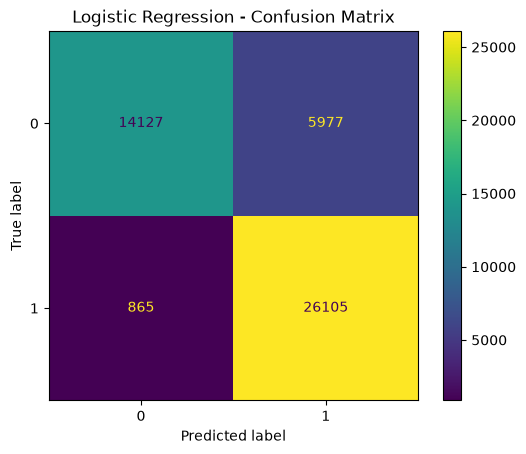

In [18]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr)
disp.plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [19]:
sample = X_test.copy()

# Match the feature names and order used during training
sample = sample[logistic_model.feature_names_in_]

# Make predictions
prediction = logistic_model.predict(sample)

# Create a side-by-side comparison table
comparison = pd.DataFrame({
    'Predicted Value': prediction,
    'Actual Value': y_test.values
})

# Check whether predictions are correct
comparison['Correct Prediction'] = (
    comparison['Predicted Value'] == comparison['Actual Value']
)

# Display the results
display(comparison)

print(comparison['Correct Prediction'].value_counts(normalize=True) * 100)

,Predicted Value,Actual Value,Correct Prediction
0,0,0,True
1,1,1,True
2,1,1,True
3,0,0,True
4,1,0,False
...,...,...,...
47069,0,0,True
47070,0,0,True
47071,1,1,True
47072,1,1,True


Correct Prediction
True     85.465437
False    14.534563
Name: proportion, dtype: float64


In [20]:
legitimate_data = np.array([
    [0,  9, 0, 1, 0.100, 0.000, 0.900, 0, 3, 1],
    [0, 10, 0, 1, 0.091, 0.000, 0.909, 0, 3, 1],
    [0, 12, 0, 1, 0.077, 0.000, 0.923, 0, 3, 1],
    [0,  9, 0, 1, 0.100, 0.000, 0.900, 0, 3, 1],
    [0, 14, 0, 1, 0.067, 0.000, 0.933, 0, 3, 1],
    [0, 11, 0, 1, 0.083, 0.000, 0.917, 0, 3, 1],
    [0, 13, 0, 1, 0.071, 0.000, 0.929, 0, 3, 1],
    [0, 15, 0, 1, 0.063, 0.000, 0.938, 0, 3, 1],
    [0, 10, 0, 1, 0.091, 0.000, 0.909, 0, 3, 1],
    [0, 12, 0, 1, 0.077, 0.000, 0.923, 0, 3, 1],
    [0, 13, 1, 1, 0.067, 0.067, 0.867, 0, 3, 1], # Sample with 1 digit
    [0, 10, 1, 1, 0.083, 0.083, 0.833, 0, 3, 1], # Sample with 1 digit
    [0, 12, 1, 1, 0.071, 0.071, 0.857, 0, 3, 1], # Sample with 1 digit
    [0, 15, 1, 1, 0.059, 0.059, 0.882, 0, 3, 1], # Sample with 1 digit
    [0, 16, 1, 1, 0.056, 0.056, 0.889, 0, 3, 1], # Sample with 1 digit

    # === PHISHING SAMPLES (IsHTTPS = 0) ===
    # Formats: ://example.com, secure-update.example.net, etc.
    [0, 25, 0, 4, 0.138, 0.000, 0.862, 2, 3, 0],
    [0, 27, 0, 4, 0.129, 0.000, 0.871, 2, 3, 0],
    [0, 28, 0, 4, 0.125, 0.000, 0.875, 2, 3, 0],
    [0, 26, 0, 4, 0.133, 0.000, 0.867, 2, 3, 0],
    [0, 29, 0, 4, 0.121, 0.000, 0.879, 2, 3, 0],
    [0, 24, 0, 4, 0.143, 0.000, 0.857, 2, 3, 0],
    [0, 30, 0, 4, 0.118, 0.000, 0.882, 2, 3, 0],
    [0, 31, 0, 4, 0.114, 0.000, 0.886, 2, 3, 0],
    [0, 31, 1, 4, 0.111, 0.028, 0.861, 2, 3, 0], # Sample with 1 digit
    [0, 32, 1, 4, 0.108, 0.027, 0.865, 2, 3, 0], # Sample with 1 digit
    [0, 33, 1, 4, 0.105, 0.026, 0.868, 2, 3, 0], # Sample with 1 digit
    [0, 34, 1, 4, 0.103, 0.026, 0.872, 2, 3, 0], # Sample with 1 digit
    [0, 35, 1, 4, 0.100, 0.025, 0.875, 2, 3, 0], # Sample with 1 digit
    [0, 36, 1, 4, 0.098, 0.024, 0.878, 2, 3, 0], # Sample with 1 digit
    [0, 37, 1, 4, 0.095, 0.024, 0.881, 2, 3, 0]
])

# Get the exact feature names used during training
feature_names = logistic_model.feature_names_in_

# Check the number of features
assert legitimate_data.shape[1] == len(feature_names), (
    "The number of input columns does not match the model features."
)

# Convert the array to a DataFrame
sample = pd.DataFrame(
    legitimate_data,
    columns=feature_names
)

# Predict classes
prediction = logistic_model.predict(sample)

# Predict probabilities
probabilities = logistic_model.predict_proba(sample)

# Display results
results = pd.DataFrame({
    "Prediction": prediction,
    "Confidence": probabilities.max(axis=1)
})

print(results)

    Prediction  Confidence
0            1    0.908210
1            1    0.896819
2            1    0.870192
3            1    0.908210
4            1    0.837869
5            1    0.884182
6            1    0.854791
7            1    0.819409
8            1    0.896819
9            1    0.870192
10           1    0.662216
11           1    0.742857
12           1    0.690534
13           1    0.601989
14           1    0.570514
15           0    0.915711
16           0    0.933751
17           0    0.941365
18           0    0.925225
19           0    0.948154
20           0    0.905111
21           0    0.954200
22           0    0.959566
23           0    0.986088
24           0    0.987766
25           0    0.989245
26           0    0.990546
27           0    0.991691
28           0    0.992699
29           0    0.993586


In [21]:
import numpy as np
import pandas as pd

# Extract features from the URL
url = "https://what.is.my.ip.address.com"
features = features_extract(url)

# Convert features into a DataFrame
sample = pd.DataFrame([features])

# Ensure the feature order matches training data
sample = sample[X.columns]

# Get the original prediction
prediction = logistic_model.predict(sample)

# Calculate class probabilities
probabilities = logistic_model.predict_proba(sample)

# Calculate confidence (highest predicted class probability)
confidence = probabilities.max(axis=1)

# Change prediction to 1 if confidence is below 0.95
prediction[confidence < 0.9] = 1

# Display results
results = pd.DataFrame({
    "URL": [url],
    "Prediction": prediction,
    "Confidence": confidence
})

print(results)

                                 URL  Prediction  Confidence
0  https://what.is.my.ip.address.com           1    0.958657


In [22]:

features = features_extract("https://www.docker.com/")

probabilities = logistic_model.predict_proba(sample)

sample = pd.DataFrame([features])

sample = sample[X.columns]

# Get the original predictions
prediction = logistic_model.predict(sample)

# Calculate confidence
confidence = probabilities.max(axis=1)

prediction[confidence < 0.95] = 1

# Display results
results = pd.DataFrame({
    "Prediction": prediction,
    "Confidence": confidence
})

print(results)

   Prediction  Confidence
0           1    0.958657


In [23]:
class PhishingDetector:
    def __init__(self, model, threshold=0.95):
        self.model = model
        self.threshold = threshold

    def predict(self, X):
        probabilities = self.model.predict_proba(X)
        predictions = self.model.predict(X)

        confidence = probabilities.max(axis=1)

        # If confidence is below 60%, change prediction to 1
        predictions[confidence < self.threshold] = 1

        return predictions

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict_with_confidence(self, X):
        probabilities = self.model.predict_proba(X)
        predictions = self.model.predict(X)
        confidence = probabilities.max(axis=1)

        predictions[confidence < self.threshold] = 1

        return predictions, confidence

In [24]:
detector = PhishingDetector(
    model=logistic_model,
    threshold=0.95
)

joblib.dump(detector, "phishing_detector.pkl")

print("Model and confidence rule saved successfully!")

Model and confidence rule saved successfully!


In [25]:
# # Load the saved detector
# detector = joblib.load("phishing_detector.pkl")

# # Predict using your existing DataFrame
# prediction, confidence = detector.predict_with_confidence(sample)

# results = pd.DataFrame({
#     "Website": ["Google", "YouTube", "Wikipedia", "GitHub",
#                 "Fake", "fake", "fake", "fake",
#                 "paypal-login", "secure-update", "verify-account", "banking-login",
#                 "Netflix spoof variation", "Wallet validation spoof", "Support portal spoof",
#                 "E-commerce checkout spoof"],
#     "Prediction": prediction,
#     "Confidence": confidence
# })

# print(results)